# 06 · ML Baselines: Text Sentiment Classification

**Purpose:** build and evaluate the first classifiers that predict a tweet's sentiment (Negative / Neutral / Positive) from its text.

**Questions answered**
- How much better than a trivial baseline can simple TF-IDF models do?
- Which metric should be used to compare models on imbalanced classes?
- Which classes and errors are hardest?

The modelling notebooks build on each other:

| Notebook | Content |
|---|---|
| **06 ML baselines** | Text cleaning, TF-IDF, Dummy / Naive Bayes / Logistic Regression baselines |
| 07 Model tuning | GridSearchCV, top terms per class, error analysis, airline subgroups |
| 08 Advanced NLP | Word + character TF-IDF, leakage-free stability check, "Can't Tell" complaint routing |
| 09 Metadata analysis | Non-text model and a like-for-like comparison with the text model |
| 10 Final model | Sentiment-aware preprocessing, richer features, NB-weighted Logistic Regression |

> **Labels vs predictions:** the descriptive analysis (notebooks 03–05) uses the sentiment labels supplied with the dataset. The models here *predict* those labels from text, for evaluation and for new tweets. Predictions never replace the supplied labels.

All reusable code (cleaning, features, model builders, metrics) lives in `src/`, so every notebook uses the same definitions.

## 0. Setup

In [1]:
import sys
from pathlib import Path

# Make the project's src/ package importable from any folder inside the repository
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "__init__.py").exists())
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.dummy import DummyClassifier
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer

from src.config import RANDOM_STATE, SENTIMENT_LABELS
from src.data import load_clean_tweets, split_train_test
from src.evaluation import fit_and_score
from src.features import word_tfidf
from src.modeling import build_word_lr
from src.plotting import PRIMARY_COLOR, SENTIMENT_COLORS, apply_style
from src.preprocessing import clean_texts, clean_tweet, mask_user_handles

apply_style()

df = load_clean_tweets()
print(f"Rows: {len(df):,}")

Rows: 14,481


## 1. Text Preprocessing

Tweets are short, informal and full of Twitter-specific tokens. A light, documented clean-up is applied:

| Step | Example | Why |
|---|---|---|
| Decode HTML entities | `&amp;` → `&` | The source stores some characters as HTML codes |
| Lower-case | `Thanks` → `thanks` | "Thanks" and "thanks" should be the same word |
| Remove URLs | `http://t.co/...` → removed | Links carry no sentiment and are unique per tweet |
| Remove @mentions | `@united` → removed | Handles identify the **airline**, not the sentiment. Keeping them lets the model learn "which airline" instead of "what the customer feels", |
| Normalise apostrophes | `don’t` → `don't` | Curly and straight apostrophes should give the same token |
| Collapse whitespace | | Tidy tokens |

Stop words ("not", "no", "never") are **kept**, because negation changes meaning ("not happy"). No stemming or lemmatisation is used; character n-grams (notebook 08) handle spelling variants.

The function is `src.preprocessing.clean_tweet`. Inside every model pipeline it runs as the first step, so models take **raw tweet text**.

In [2]:
df["clean_text"] = df["text"].map(clean_tweet)

examples = df.sample(5, random_state=RANDOM_STATE)[["airline_sentiment", "text", "clean_text"]]
examples.assign(text=examples["text"].map(mask_user_handles))

,airline_sentiment,text,clean_text
11610,Negative,@USAirways @user Mr. Husain u shld protest as ...,mr. husain u shld protest as well when one of ...
9902,Negative,@usairways @AmericanAir LAX connect from term ...,lax connect from term 6 to term 4. 55min layov...
1795,Neutral,@united no thank you,no thank you
12801,Negative,@AmericanAir yes there's issues on the site as...,yes there's issues on the site as well unfortu...
6051,Neutral,@SouthwestAir I am now a rapids rewards member...,i am now a rapids rewards member #lovetotravel...


In [3]:
# Basic text statistics after cleaning
word_counts = df["clean_text"].str.split().str.len()
print(f"Average words per tweet: {word_counts.mean():.1f} (median {word_counts.median():.0f})")
print(f"Tweets empty after cleaning: {(word_counts == 0).sum()}")
display(word_counts.groupby(df["airline_sentiment"]).mean().round(1).reindex(SENTIMENT_LABELS).to_frame("avg_words"))

Average words per tweet: 16.5 (median 18)
Tweets empty after cleaning: 0


,avg_words
airline_sentiment,
Negative,18.6
Neutral,13.2
Positive,12.9


**Observation:** Negative tweets are the longest on average. Customers explain what went wrong, while positive tweets are usually short thanks.

## 2. Train / Test Split

- Target: the supplied `airline_sentiment` label (3 classes)
- Stratified 80/20 split with `random_state = 42` (`src.data.split_train_test`), shared by notebooks 06–10
- Cleaning and vectorisers run **inside pipelines fitted on the training data only**, so no vocabulary or IDF weight is learned from the test set

In [4]:
train_df, test_df = split_train_test(df)
X_train, y_train = train_df["text"], train_df["airline_sentiment"]
X_test, y_test = test_df["text"], test_df["airline_sentiment"]

print(f"Training tweets: {len(train_df):,} | Test tweets: {len(test_df):,}")
display(pd.DataFrame({
    "train_pct": y_train.value_counts(normalize=True) * 100,
    "test_pct": y_test.value_counts(normalize=True) * 100,
}).reindex(SENTIMENT_LABELS).round(2))

Training tweets: 11,584 | Test tweets: 2,897


,train_pct,test_pct
airline_sentiment,,
Negative,62.72,62.72
Neutral,21.18,21.19
Positive,16.11,16.09


## 3. How TF-IDF Works (brief)

Each tweet becomes a vector of weights, one per word or character sequence:

- **TF (term frequency):** how often the term appears in the tweet (`sublinear_tf=True` uses 1 + log(count), so repeating a word 5 times does not count 5×)
- **IDF (inverse document frequency):** rare terms get higher weight, while very common terms ("the", "flight") get lower weight
- **TF-IDF = TF × IDF**

Two views of the text are combined:
- **Word n-grams (1–2):** single words and pairs such as `"not happy"` or `"on hold"`
- **Character n-grams (3–5, within word boundaries):** robust to misspellings, slang and hashtags (`"thx"`, `"thanksss"`, `#fail`)

## 4. Baseline Models

Models are compared on the **same split** with three metrics:
- **Accuracy:** share of correct predictions (misleading here, since always predicting "Negative" already scores ~63%)
- **Macro-F1:** F1 averaged equally over the three classes. This is the **main metric**, because it rewards getting the minority classes right
- **Weighted-F1:** F1 weighted by class size
- **Macro precision / recall:** averaged over classes, to show whether errors are false alarms or misses

In [5]:
def text_pipeline(model):
    """Basic cleaning -> word TF-IDF -> model."""
    return Pipeline([("clean", FunctionTransformer(clean_texts)), ("tfidf", word_tfidf()), ("model", model)])

results = [
    fit_and_score("Dummy (always Negative)", text_pipeline(DummyClassifier(strategy="most_frequent")),
                  X_train, y_train, X_test, y_test),
    fit_and_score("Multinomial Naive Bayes", text_pipeline(MultinomialNB(alpha=0.3)), X_train, y_train, X_test, y_test),
    fit_and_score("Word TF-IDF + Logistic Regression", build_word_lr(), X_train, y_train, X_test, y_test),
]
comparison = pd.DataFrame(results).set_index("model")
comparison.round(4)

,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1
model,,,,,
Dummy (always Negative),0.6272,0.2091,0.3333,0.2570,0.4835
Multinomial Naive Bayes,0.7525,0.7802,0.5837,0.6289,0.7195
Word TF-IDF + Logistic Regression,0.7957,0.7443,0.7491,0.7461,0.7979


**Observation:** every text model clearly beats the Dummy baseline on Macro-F1. Logistic Regression on word TF-IDF is the strongest baseline. Naive Bayes has decent accuracy but weaker Macro-F1, because it under-predicts the smaller Neutral and Positive classes.

## 5. Cross-Validation of the Logistic Regression Baseline

A single test split can be lucky or unlucky. 5-fold cross-validation **on the training set** shows how stable the baseline is. The spread is a fold-to-fold standard deviation, not a confidence interval.

In [6]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_scores = cross_val_score(build_word_lr(), X_train, y_train, cv=cv, scoring="f1_macro", n_jobs=-1)

print(f"5-fold CV Macro-F1 (training set): {cv_scores.mean():.4f} +/- {cv_scores.std():.4f}")
print("Fold scores:", np.round(cv_scores, 4))

5-fold CV Macro-F1 (training set): 0.7405 +/- 0.0093
Fold scores: [0.7397 0.7502 0.7254 0.7367 0.7503]


## 6. Model Comparison Chart

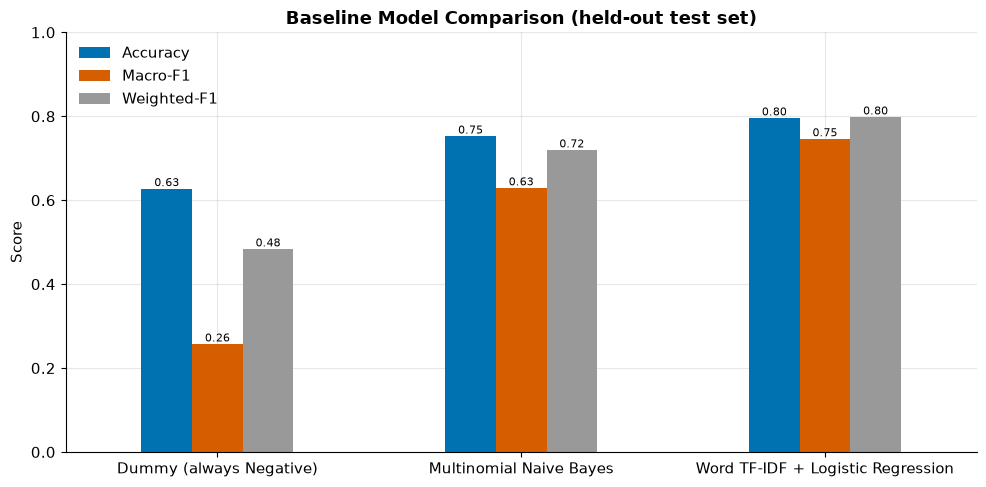

In [7]:
fig, ax = plt.subplots(figsize=(10, 5))
comparison[["accuracy", "macro_f1", "weighted_f1"]].plot(
    kind="bar", color=[PRIMARY_COLOR, SENTIMENT_COLORS["Negative"], SENTIMENT_COLORS["Neutral"]], ax=ax)
ax.set_ylim(0, 1)
ax.set_title("Baseline Model Comparison (held-out test set)")
ax.set_xlabel("")
ax.set_ylabel("Score")
ax.tick_params(axis="x", rotation=0)
ax.legend(["Accuracy", "Macro-F1", "Weighted-F1"], loc="upper left")
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", fontsize=8)
plt.tight_layout()
plt.show()

**Observation:** the Dummy model's accuracy (about 63%) looks respectable only because most tweets are Negative. Its Macro-F1 exposes that it never predicts Neutral or Positive. Accuracy alone is therefore not used to choose models.

## 7. Logistic Regression: Class-wise Results and Confusion Matrix

              precision    recall  f1-score   support

    Negative      0.882     0.858     0.870      1817
     Neutral      0.602     0.666     0.633       614
    Positive      0.749     0.723     0.736       466

    accuracy                          0.796      2897
   macro avg      0.744     0.749     0.746      2897
weighted avg      0.801     0.796     0.798      2897



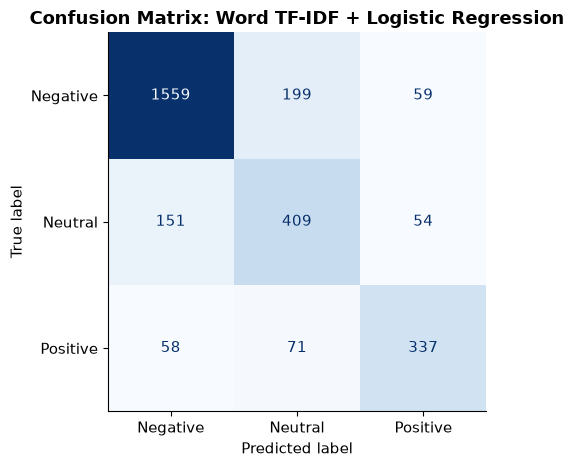

In [8]:
baseline_lr = build_word_lr().fit(X_train, y_train)
baseline_predictions = baseline_lr.predict(X_test)
print(classification_report(y_test, baseline_predictions, labels=SENTIMENT_LABELS, digits=3))

fig, ax = plt.subplots(figsize=(5.5, 4.8))
ConfusionMatrixDisplay.from_predictions(y_test, baseline_predictions, labels=SENTIMENT_LABELS,
                                        cmap="Blues", ax=ax, colorbar=False)
ax.set_title("Confusion Matrix: Word TF-IDF + Logistic Regression")
ax.grid(False)
plt.tight_layout()
plt.show()

**Interpretation:** Negative has the highest F1 and Neutral the lowest. Most errors sit on the Negative ↔ Neutral boundary, where enquiries and mild complaints use similar words. Notebook 07 tunes this model and examines those errors in detail.

## 8. Conclusions

In [9]:
best_basic = comparison["macro_f1"].idxmax()
print(f"1. Best basic model: {best_basic} (test Macro-F1 {comparison.loc[best_basic, 'macro_f1']:.4f}, "
      f"accuracy {comparison.loc[best_basic, 'accuracy']:.4f}).")
print(f"2. Dummy baseline Macro-F1: {comparison.loc['Dummy (always Negative)', 'macro_f1']:.4f}, so text adds real signal.")
print(f"3. 5-fold cross-validated (training set) Macro-F1 of the Logistic Regression baseline: {cv_scores.mean():.4f} +/- {cv_scores.std():.4f}.")

1. Best basic model: Word TF-IDF + Logistic Regression (test Macro-F1 0.7461, accuracy 0.7957).
2. Dummy baseline Macro-F1: 0.2570, so text adds real signal.
3. 5-fold cross-validated (training set) Macro-F1 of the Logistic Regression baseline: 0.7405 +/- 0.0093.


- Classical text features (TF-IDF) with a linear model already beat the baseline by a wide margin.
- Logistic Regression is the strongest and most interpretable basic model, so it is carried forward to tuning (notebook 07).
- Neutral is the hardest class to recognise.